# Homework 7: Practicing Regression

### Part 1

Let's practice linear regression using a real estate dataset with information on home prices and other attributes like square footage and garage size.

In [1]:
# Import your libraries... 
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import statsmodels.formula.api as smf

In [2]:
# Check out the data... 
df = pd.read_csv('data/real_estate_dataset.csv')
df.dtypes

ID                      int64
Square_Feet           float64
Num_Bedrooms            int64
Num_Bathrooms           int64
Num_Floors              int64
Year_Built              int64
Has_Garden              int64
Has_Pool                int64
Garage_Size             int64
Location_Score        float64
Distance_to_Center    float64
Price                 float64
dtype: object

In [3]:
df.head()

,ID,Square_Feet,Num_Bedrooms,Num_Bathrooms,Num_Floors,Year_Built,Has_Garden,Has_Pool,Garage_Size,Location_Score,Distance_to_Center,Price
0,1,143.635030,1,3,3,1967,1,1,48,8.297631,5.935734,602134.816747
1,2,287.678577,1,2,1,1949,0,1,37,6.061466,10.827392,591425.135386
2,3,232.998485,1,3,2,1923,1,0,14,2.911442,6.904599,464478.696880
3,4,199.664621,5,2,2,1918,0,0,17,2.070949,8.284019,583105.655996
4,5,89.004660,4,3,3,1999,1,0,34,1.523278,14.648277,619879.142523


Question: What factors explain differences in housing prices, and how well can we predict the price of a house using its characteristics?

Let's start simple with the question... Does house size affect price?

Fill in the blank: \
The independent variable in this analysis is _________. The dependent variable is _________. \
The regression formula is ________.


In [4]:
# Ok now let's perform the simple linear regression. Write your code below.
# Independent = house size (Square_Feet)
# Dependent = price (Price)

# Regression formula:
x = df["Square_Feet"]
y = df["Price"]

model = sm.OLS(y, x)

results = model.fit()

In [5]:
results.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                                 OLS Regression Results                                
=======================================================================================
Dep. Variable:                  Price   R-squared (uncentered):                   0.893
Model:                            OLS   Adj. R-squared (uncentered):              0.893
Method:                 Least Squares   F-statistic:                              4172.
Date:                Mon, 09 Nov 2026   Prob (F-statistic):                   1.71e-244
Time:                        08:43:08   Log-Likelihood:                         -6798.4
No. Observations:                 500   AIC:                                  1.360e+04
Df Residuals:                     499   BIC:                                  1.360e+04
Df Model:                           1                                                  
Covariance Type:            nonrobust                                                  
===============================================================================
                  coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------
Square_Feet  2960.4944     45.834     64.592      0.000    2870.444    3050.545
==============================================================================
Omnibus:                       33.308   Durbin-Watson:                   1.708
Prob(Omnibus):                  0.000   Jarque-Bera (JB):               12.647
Skew:                          -0.077   Prob(JB):                      0.00179
Kurtosis:                       2.236   Cond. No.                         1.00
==============================================================================

Notes:
[1] R² is computed without centering (uncentered) since the model does not contain a constant.
[2] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

Text(0, 0.5, 'Price (Millions)')

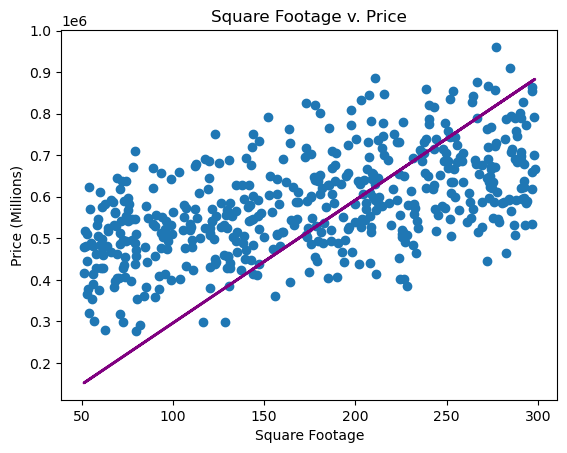

In [6]:
# Plot your data on a scatterplot and draft a regression line. Write your code below.

plt.scatter(df["Square_Feet"], df["Price"])

plt.plot(
    df["Square_Feet"],
    results.predict(),
    color = "purple",
    linewidth = 2,
    label = "Regression Line"
)

plt.title("Square Footage v. Price")
plt.xlabel("Square Footage")
plt.ylabel("Price (Millions)")

Ok, let's take it a step further. Our new question is: Does house size still matter when we control for the number of bedrooms and bathrooms?

Fill in the blank: 

The independent variable in this analysis is _________. 

The dependent variable is _________. 

The control variables are ________. 

The regression formula is ________. 

I'll help you with the code for the next part.

In [7]:
# Independant = Square_Feet
# Dependent = Price
# Control = Num_Bedrooms, Num_Bathrooms

# Regression formula:

x = df["Square_Feet"]
y = df["Price"]


# Run multiple linear regression
model = smf.ols("Price ~ Square_Feet + Num_Bedrooms + Num_Bathrooms", data=df).fit()

# Display results
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:                  Price   R-squared:                       0.700
Model:                            OLS   Adj. R-squared:                  0.698
Method:                 Least Squares   F-statistic:                     385.7
Date:                Mon, 09 Nov 2026   Prob (F-statistic):          3.29e-129
Time:                        08:43:08   Log-Likelihood:                -6265.0
No. Observations:                 500   AIC:                         1.254e+04
Df Residuals:                     496   BIC:                         1.255e+04
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
Intercept      2.055e+05   1.26e+04     16.270

In [8]:
# My model explains 70% of the variation in house prices, and 3 of my 3 explanatory variables are statistically significant.
# When sq footage is 0, the predicted house price is $205,500.
# For every additional square foot, we can expect the predicted house price to increase by $964.62.

Fill in the blank: 

Your model explains _____% of the variation in house prices, and _____ of my 3 explanatory variables are statistically significant.

When square footage is zero, the predicted house price is _____.

For every additional square foot, we can expect the predicted house price to increase by _____ units, on average.


### Part 2

Read the main article in the Tampa Bay Times' Pulitzer Prize-winning series Failure Factories:\
https://projects.tampabay.com/projects/2015/investigations/pinellas-failure-factories/5-schools-segregation/

And then read the criticism of it in Forbes:\
https://www.forbes.com/sites/maureensullivan/2016/04/29/here-are-the-holes-in-the-pulitzer-winning-failure-factories-series-on-segregated-schools/

Answer the following questions (in at least 3 sentences each), which we will discuss further in class:

1. What are your thoughts on the Tampa Bay Times' series? What parts of it do you find valuable to readers?

2. The series got a scathing critique in Forbes. What are your thoughts on the critique? Do you find it compelling? What do you think the journalists at the Florida newsroom should have done differently? 

1. The Tampa Bar Times' series immediately struck me as interesting, and did draw me in. I was curious about what had happened, but also confused because the story continually referred to a "re-segregation" that it felt like I was supposed to already know about and understand. Towards the bottom of the story, I feel like I actually started to understand what (at least the Times' reporters thought) had happened. I thought, however, that the statistics were interesting and set me up for learning about what had happened later in the story (though again, I think I would've been less confused if they wove some of what exactly the "resegregation" was a little bit earlier in the story). The way the reporters discussed the statistics, however, without much about what actually happened, made it sound almost like they were blaming bad test scores on Black children, and that if white children were simply added to the equation, this wouldn't be the case. I would have liked more information and statistics about how integration benefits both Black and white children (I'm having trouble finding it again, but I know they referenced a study regarding how integration impacts childrens' test scores once, but only once). I also thought that the way that the reporters referred to Black children was a little weird — I think that the statistics, though interesting, made it feel like the students they were speaking about were simply another number in an equation.
2. I definitely found the critique in Forbes to be enlightening. I was first off, surprised to hear that the Times' had been pro-"resegreation" at the time that it was being decided, and somehow, none of the reporters thought it would be a good idea to mention that in the story. This would've added some interesting context, in my opinon, and given a fuller picture of how opinions were being shaped at the time. The school board clearly wasn't alone in thinking that getting rid of bussing might be a good idea. Secondly, I think the discussion of the way that teachers are hired at these schools was essential for the Times' story. It even included anecdotes and information about the teachers' struggles at the schools, but I would have liked to know about how that is systematically encouraged, instead of being spelled out as though it's an anomaly that came along with the "re-segregation" of these schools. 